# 逻辑回归课堂笔记：从概率到分类

本 Notebook 按《机器学习课堂笔记(9)》第 4 章整理，并补充讲义没有展开的部分：

- 信贷审批业务与 T/P/E
- 线性回归做分类的两个问题
- Sigmoid 函数、导数与决策边界
- 交叉熵损失与梯度下降
- sklearn `LogisticRegression` + `ColumnTransformer` + `Pipeline`
- 混淆矩阵、Precision / Recall / F1、ROC-AUC、PR-AUC
- 阈值选择与业务成本
- 类别不平衡 `class_weight`
- 正则化参数 `C`
- 系数与优势比解释

数据：`../data/信贷数据.csv`（课程示例数据，6000 条申请记录，9 个特征，目标为 `是否违约`）。

依赖：

```bash
pip install numpy pandas scikit-learn matplotlib
```

> Notebook 位于 `notebooks/` 目录，因此数据路径写作 `../data/信贷数据.csv`；如果在项目根目录运行，请改成 `data/信贷数据.csv`。

## 0. 环境与绘图设置

先统一导入依赖、字体和随机种子。后面的模型都使用 `random_state=42`，保证划分和结果可复现。

In [1]:
%matplotlib inline

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    auc,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict,
    GridSearchCV,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 160
np.set_printoptions(precision=4, suppress=True)

# 逻辑回归在 max_iter=2000 下通常能收敛；个别数据会提示收敛警告，这里只屏蔽该警告
warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_STATE = 42
FN_COST = 30_000   # 批给一个最终违约的人，公司损失约 3 万元
FP_COST = 3_000    # 拒掉一个会按时还款的好客户，损失约 3000 元利润

IMAGES = Path("images")
IMAGES.mkdir(exist_ok=True)

## 1. 业务问题：信贷审批

一家消费金融公司每天收到大量贷款申请，审批员要决定“批”还是“不批”。

两类错误的代价完全不同：

- **FN（漏掉违约者）**：本来会违约，模型却批了，平均损失约 **3 万元**本金；
- **FP（误伤好客户）**：本来会按时还款，模型却拒了，损失约 **3000 元**利润。

用 T、P、E 描述：

| 要素 | 内容 |
|---|---|
| 任务 T | 判断申请人会不会违约 |
| 性能 P | 抓住了多少违约者、误伤了多少好客户，最终落到“公司损失多少钱” |
| 经验 E | 过去的申请记录，以及它们最后是否违约 |

这是一个**二分类**问题。好的分类模型不只输出“违约/不违约”，而是输出**违约概率**；再根据业务风险偏好设定阈值，决定批不批。

In [2]:
# Notebook 位于 notebooks/ 目录，因此用 ../data 回到项目根目录
df = pd.read_csv("../data/信贷数据.csv")

print("数据形状:", df.shape)
print("缺失值总数:", int(df.isna().sum().sum()))
print("违约比例:", f"{df['是否违约'].mean():.2%}")
df.head()

数据形状: (6000, 10)
缺失值总数: 0
违约比例: 14.65%


,年龄,月收入,负债收入比,额度使用率,逾期次数,工作年限,学历,住房,职业,是否违约
0,29,5800,0.545,0.434,1,2.6,本科,有房贷,公职,1
1,47,8400,0.484,0.259,0,3.4,本科,租房,公职,0
2,23,6600,0.336,0.519,2,3.7,大专,有房贷,公职,1
3,28,3900,0.336,0.809,2,1.4,大专,租房,公职,0
4,33,8600,0.448,0.364,1,7.1,高中及以下,租房,餐饮零售,0


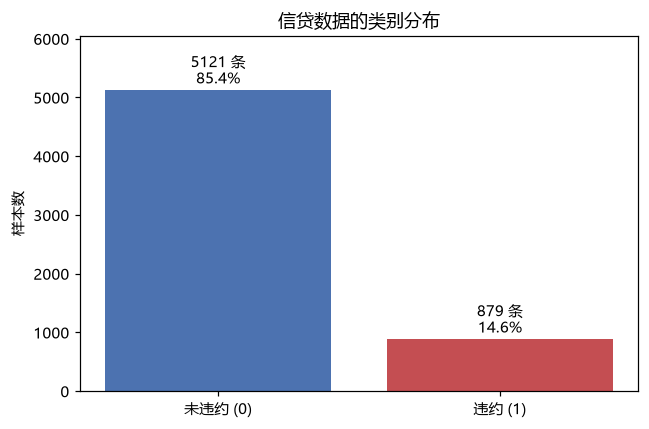

In [3]:
target_counts = df["是否违约"].value_counts().sort_index()
target_ratio = df["是否违约"].value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(
    ["未违约 (0)", "违约 (1)"],
    target_counts.values,
    color=["#4C72B0", "#C44E52"],
)
ax.set_ylabel("样本数")
ax.set_title("信贷数据的类别分布")
for bar, count, ratio in zip(bars, target_counts.values, target_ratio.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 50,
        f"{count} 条\n{ratio:.1%}",
        ha="center",
        va="bottom",
        fontsize=10,
    )
ax.set_ylim(0, target_counts.max() * 1.18)
plt.tight_layout()
plt.savefig(IMAGES / "notes9_fig_target.png", bbox_inches="tight")
plt.show()

数据共 **6000 条**，其中未违约 5121 条（85.4%）、违约 879 条（14.6%）。

这就是**类别不平衡**。如果模型什么都不学，永远猜“未违约”，准确率也有 85.4%，但一个违约者也抓不到。所以后续不能只看 accuracy，还要看召回率、PR-AUC 和业务成本。

> 对应讲义第 54 页的信贷数据示例。

## 2. 线性回归做分类：输出越界与远端样本拉偏

讲义先用一个 20 人的小例子：记录复习时长 `hours` 和是否通过 `passed`（通过 = 1，未通过 = 0）。

最自然的想法是把 0/1 当成数，用线性回归拟合一条直线，预测值 `>= 0.5` 就判为“通过”。直线与 0.5 的交点就是模型心中的“及格线”。

对应讲义第 55–56 页图 2-1。

In [4]:
hours = np.array(
    [1, 2, 2.5, 3, 4, 4.5, 5, 5.5, 6, 6.5,
     7, 7.5, 8, 9, 10, 11, 12, 13, 14, 15],
    dtype=float,
)
passed = np.array(
    [0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
     1, 0, 1, 1, 1, 1, 1, 1, 1, 1],
    dtype=int,
)

X_hours = hours.reshape(-1, 1)
lin_clf = LinearRegression().fit(X_hours, passed)

cut = (0.5 - lin_clf.intercept_) / lin_clf.coef_[0]
acc = ((lin_clf.predict(X_hours) >= 0.5) == passed).mean()

print(f"直线: y = {lin_clf.coef_[0]:.4f}x {lin_clf.intercept_:+.4f}")
print(f"及格线: {cut:.2f} 小时")
print(f"训练集准确率: {acc:.2f}")
print(f"复习 30 小时的预测值: {lin_clf.predict([[30]])[0]:.3f}")

直线: y = 0.0929x -0.1305
及格线: 6.79 小时
训练集准确率: 0.85
复习 30 小时的预测值: 2.656


In [5]:
# 加入 3 位“超级学霸”：50、60、70 小时，当然都通过了
hours2 = np.append(hours, [50, 60, 70]).reshape(-1, 1)
passed2 = np.append(passed, [1, 1, 1])
lin_clf2 = LinearRegression().fit(hours2, passed2)

cut2 = (0.5 - lin_clf2.intercept_) / lin_clf2.coef_[0]
acc_all = ((lin_clf2.predict(hours2) >= 0.5) == passed2).mean()
acc_original = ((lin_clf2.predict(X_hours) >= 0.5) == passed).mean()

print(f"加入 3 位学霸后直线: y = {lin_clf2.coef_[0]:.4f}x {lin_clf2.intercept_:+.4f}")
print(f"及格线: {cut2:.2f} 小时")
print(f"23 个样本的准确率: {acc_all:.2f}")
print(f"原来 20 人的准确率: {acc_original:.2f}")

pd.DataFrame({
    "方案": ["原来 20 人", "加入 3 位学霸"],
    "直线": [
        f"y={lin_clf.coef_[0]:.4f}x{lin_clf.intercept_:+.4f}",
        f"y={lin_clf2.coef_[0]:.4f}x{lin_clf2.intercept_:+.4f}",
    ],
    "及格线(小时)": [cut, cut2],
    "准确率(建模样本)": [acc, acc_all],
    "准确率(原 20 人)": [acc, acc_original],
}).round(3)

加入 3 位学霸后直线: y = 0.0118x +0.4408
及格线: 5.00 小时
23 个样本的准确率: 0.83
原来 20 人的准确率: 0.80


,方案,直线,及格线(小时),准确率(建模样本),准确率(原 20 人)
0,原来 20 人,y=0.0929x-0.1305,6.787,0.850,0.85
1,加入 3 位学霸,y=0.0118x+0.4408,5.003,0.826,0.80


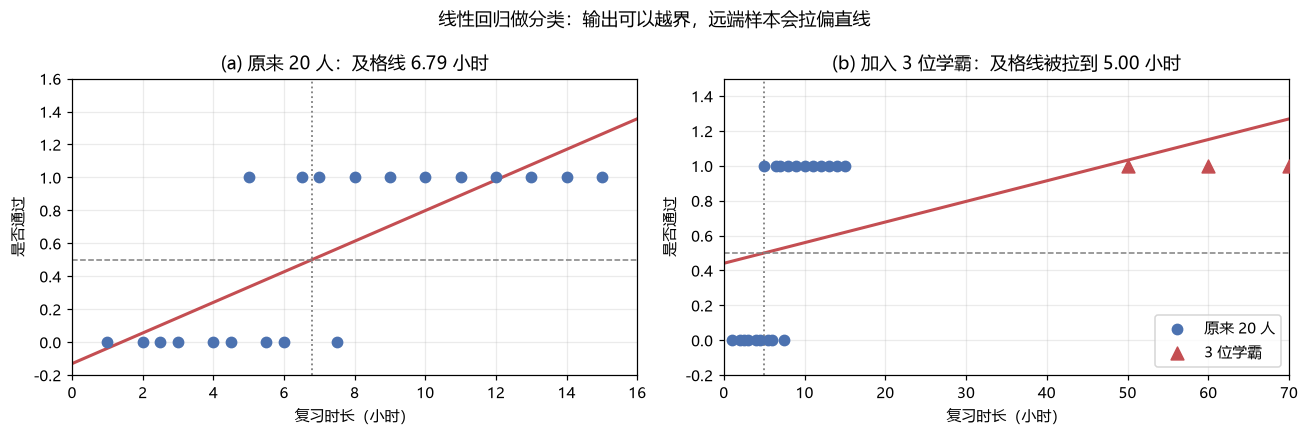

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

x1 = np.linspace(0, 16, 200).reshape(-1, 1)
axes[0].scatter(hours, passed, s=45, color="#4C72B0", zorder=3)
axes[0].plot(x1, lin_clf.predict(x1), color="#C44E52", linewidth=2)
axes[0].axhline(0.5, color="gray", linestyle="--", linewidth=1)
axes[0].axvline(cut, color="gray", linestyle=":", linewidth=1.2)
axes[0].set_xlim(0, 16)
axes[0].set_ylim(-0.2, 1.6)
axes[0].set_xlabel("复习时长（小时）")
axes[0].set_ylabel("是否通过")
axes[0].set_title(f"(a) 原来 20 人：及格线 {cut:.2f} 小时")
axes[0].grid(alpha=0.25)

x2 = np.linspace(0, 70, 300).reshape(-1, 1)
axes[1].scatter(hours, passed, s=45, color="#4C72B0", zorder=3, label="原来 20 人")
axes[1].scatter([50, 60, 70], [1, 1, 1], s=70, color="#C44E52", marker="^", zorder=3, label="3 位学霸")
axes[1].plot(x2, lin_clf2.predict(x2), color="#C44E52", linewidth=2)
axes[1].axhline(0.5, color="gray", linestyle="--", linewidth=1)
axes[1].axvline(cut2, color="gray", linestyle=":", linewidth=1.2)
axes[1].set_xlim(0, 70)
axes[1].set_ylim(-0.2, 1.5)
axes[1].set_xlabel("复习时长（小时）")
axes[1].set_ylabel("是否通过")
axes[1].set_title(f"(b) 加入 3 位学霸：及格线被拉到 {cut2:.2f} 小时")
axes[1].legend()
axes[1].grid(alpha=0.25)

fig.suptitle("线性回归做分类：输出可以越界，远端样本会拉偏直线")
plt.tight_layout()
plt.savefig(IMAGES / "notes9_fig_linear_classification.png", bbox_inches="tight")
plt.show()

结果：

- 原来 20 人：直线 `y = 0.0929x - 0.1305`，及格线 **6.79 小时**，准确率 **0.85**；复习 30 小时的预测值是 **2.656**，已经超过 1，无法解释成概率。
- 加入 3 位学霸后：直线被压平，及格线从 6.79 小时拉到 **5.00 小时**；23 个样本的准确率是 **0.83**，但原来 20 人的准确率只有 **0.80**。

> **口径说明**：0.83 是在 23 个样本（原 20 人 + 3 位学霸）上算的；0.80 是只看原来 20 人。讲义文字和代码输出并不矛盾。

两个根本问题：

1. 线性回归输出范围是 `(-∞, +∞)`，不能当概率；
2. 远端样本的残差很大，MSE 平方后惩罚更重，直线为了照顾它们而整体偏移，原来的分类边界被拉歪。

## 3. Sigmoid 函数

理想的分类函数是阶跃函数：

$$
h(z)=
\begin{cases}
1, & z \ge 0\\
0, & z < 0
\end{cases}
$$

但它在 `z=0` 处跳变、不可导；除 0 点外导数全为 0。梯度下降需要导数，所以阶跃函数“好看但没法训练”。

Sigmoid 是阶跃函数的光滑替代品：

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

三个核心性质：

1. 输出永远在 `(0,1)` 之间，可以解释成概率；
2. `σ(0)=0.5`，且 `σ(-z)=1-σ(z)`；
3. 导数可以用自身表示：

$$
\sigma'(z)=\sigma(z)\bigl(1-\sigma(z)\bigr)
$$

导数最大值在 `z=0`，等于 `0.25`；`z` 离 0 越远，导数越接近 0，这叫**饱和**。

> 对应讲义第 57–58 页图 3-1。

In [7]:
def sigmoid(z):
    """数值稳定的 Sigmoid：避免 exp 溢出。"""
    z = np.asarray(z, dtype=float)
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1.0 / (1.0 + e), e / (1.0 + e))


def sigmoid_derivative(z):
    s = sigmoid(z)
    return s * (1 - s)


for z in [-2.0, 0.0, 2.0]:
    print(f"z={z:>4.1f}  sigma(z)={float(sigmoid(z)):.4f}  sigma'(z)={float(sigmoid_derivative(z)):.4f}")

print("sigma(0) =", float(sigmoid(0.0)))
print("sigma(-2) + sigma(2) =", float(sigmoid(-2) + sigmoid(2)))
print("sigma'(0) =", float(sigmoid_derivative(0.0)))

z=-2.0  sigma(z)=0.1192  sigma'(z)=0.1050
z= 0.0  sigma(z)=0.5000  sigma'(z)=0.2500
z= 2.0  sigma(z)=0.8808  sigma'(z)=0.1050
sigma(0) = 0.5
sigma(-2) + sigma(2) = 0.9999999999999999
sigma'(0) = 0.25


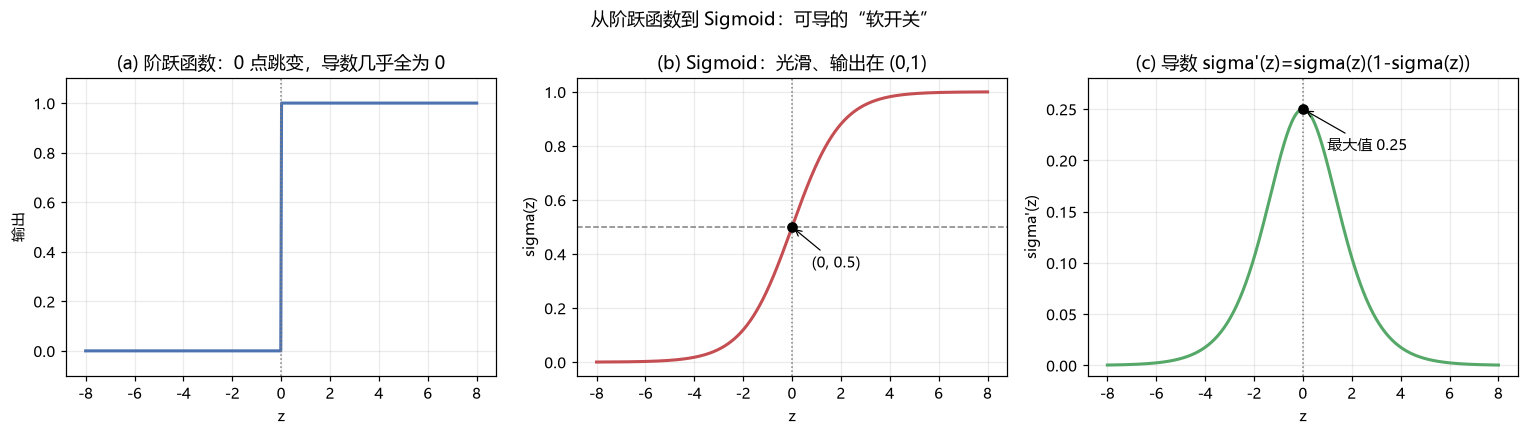

In [8]:
z = np.linspace(-8, 8, 500)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(z, (z >= 0).astype(float), color="#4C72B0", linewidth=2)
axes[0].axvline(0, color="gray", linestyle=":", linewidth=1)
axes[0].set_title("(a) 阶跃函数：0 点跳变，导数几乎全为 0")
axes[0].set_xlabel("z")
axes[0].set_ylabel("输出")
axes[0].set_ylim(-0.1, 1.1)
axes[0].grid(alpha=0.25)

axes[1].plot(z, sigmoid(z), color="#C44E52", linewidth=2)
axes[1].axhline(0.5, color="gray", linestyle="--", linewidth=1)
axes[1].axvline(0, color="gray", linestyle=":", linewidth=1)
axes[1].scatter([0], [0.5], color="black", zorder=3)
axes[1].annotate(
    "(0, 0.5)",
    xy=(0, 0.5),
    xytext=(0.8, 0.35),
    arrowprops=dict(arrowstyle="->", lw=0.8),
)
axes[1].set_title("(b) Sigmoid：光滑、输出在 (0,1)")
axes[1].set_xlabel("z")
axes[1].set_ylabel("sigma(z)")
axes[1].set_ylim(-0.05, 1.05)
axes[1].grid(alpha=0.25)

axes[2].plot(z, sigmoid_derivative(z), color="#55A868", linewidth=2)
axes[2].axvline(0, color="gray", linestyle=":", linewidth=1)
axes[2].scatter([0], [0.25], color="black", zorder=3)
axes[2].annotate(
    "最大值 0.25",
    xy=(0, 0.25),
    xytext=(1.0, 0.21),
    arrowprops=dict(arrowstyle="->", lw=0.8),
)
axes[2].set_title("(c) 导数 sigma'(z)=sigma(z)(1-sigma(z))")
axes[2].set_xlabel("z")
axes[2].set_ylabel("sigma'(z)")
axes[2].set_ylim(-0.01, 0.28)
axes[2].grid(alpha=0.25)

fig.suptitle("从阶跃函数到 Sigmoid：可导的“软开关”")
plt.tight_layout()
plt.savefig(IMAGES / "notes9_fig_sigmoid.png", bbox_inches="tight")
plt.show()

### 从 Sigmoid 到逻辑回归

把线性得分 `z = wᵀx + b` 塞进 Sigmoid：

$$
p = P(y=1\mid x) = \sigma(w^\top x + b)
$$

- `p` 是正类（违约）概率，`1-p` 是负类概率；
- 决策边界是 `z = wᵀx + b = 0`；
- 默认阈值是 `0.5`，但阈值可以根据业务成本调整；
- 训练目标不是最小化 MSE，而是最小化**交叉熵**（等价于最大化对数似然）。

## 4. 交叉熵损失与梯度下降

### 4.1 交叉熵损失

对二分类，交叉熵（对数损失）为：

$$
L(w,b)=-\frac{1}{n}\sum_{i=1}^{n}
\Bigl[y_i\log p_i+(1-y_i)\log(1-p_i)\Bigr]
$$

其中 `p_i = σ(wᵀx_i + b)`。

为什么不用 MSE？

- MSE + Sigmoid 通常是非凸的，容易卡在局部最优；
- Sigmoid 饱和时，MSE 的梯度会变得非常小，学习几乎停滞；
- 交叉熵 + Sigmoid 对参数是凸的，梯度形式也很干净：预测错得越离谱，梯度越大。

### 4.2 梯度

$$
\frac{\partial L}{\partial w}=\frac{1}{n}\sum_{i=1}^{n}(p_i-y_i)x_i,
\qquad
\frac{\partial L}{\partial b}=\frac{1}{n}\sum_{i=1}^{n}(p_i-y_i)
$$

更新规则：

$$
w \leftarrow w-\eta\frac{\partial L}{\partial w},
\qquad
b \leftarrow b-\eta\frac{\partial L}{\partial b}
$$

In [9]:
# 用 20 个学生的数据手写逻辑回归：标准化 -> 梯度下降
x_raw = hours.copy()
x_mean, x_sd = x_raw.mean(), x_raw.std()
x_scaled = (x_raw - x_mean) / x_sd
y = passed.astype(float)

w, b = 0.0, 0.0
learning_rate = 0.5
epochs = 5000
loss_history = []

for epoch in range(epochs):
    z = w * x_scaled + b
    p = sigmoid(z)
    loss = -np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12))
    loss_history.append(loss)

    dw = np.mean((p - y) * x_scaled)
    db = np.mean(p - y)
    w -= learning_rate * dw
    b -= learning_rate * db

p_final = sigmoid(w * x_scaled + b)
acc_gd = ((p_final >= 0.5) == y).mean()
boundary_scaled = -b / w
boundary_hours = x_mean + x_sd * boundary_scaled

print(f"手写梯度下降: w={w:.4f}, b={b:.4f}")
print(f"决策边界: 标准化空间 z=0 -> 复习 {boundary_hours:.2f} 小时")
print(f"训练集准确率: {acc_gd:.2f}, 最终交叉熵: {loss_history[-1]:.4f}")

# 与 sklearn 对照
sk_log = LogisticRegression(max_iter=2000).fit(x_scaled.reshape(-1, 1), y)
sk_boundary = -sk_log.intercept_[0] / sk_log.coef_[0, 0]
sk_boundary_hours = x_mean + x_sd * sk_boundary
print(
    f"sklearn: w={sk_log.coef_[0, 0]:.4f}, b={sk_log.intercept_[0]:.4f}, "
    f"边界={sk_boundary_hours:.2f} 小时, 准确率={sk_log.score(x_scaled.reshape(-1, 1), y):.2f}"
)

手写梯度下降: w=4.1123, b=1.0590
决策边界: 标准化空间 z=0 -> 复习 6.29 小时
训练集准确率: 0.90, 最终交叉熵: 0.2763
sklearn: w=1.6836, b=0.3989, 边界=6.37 小时, 准确率=0.90


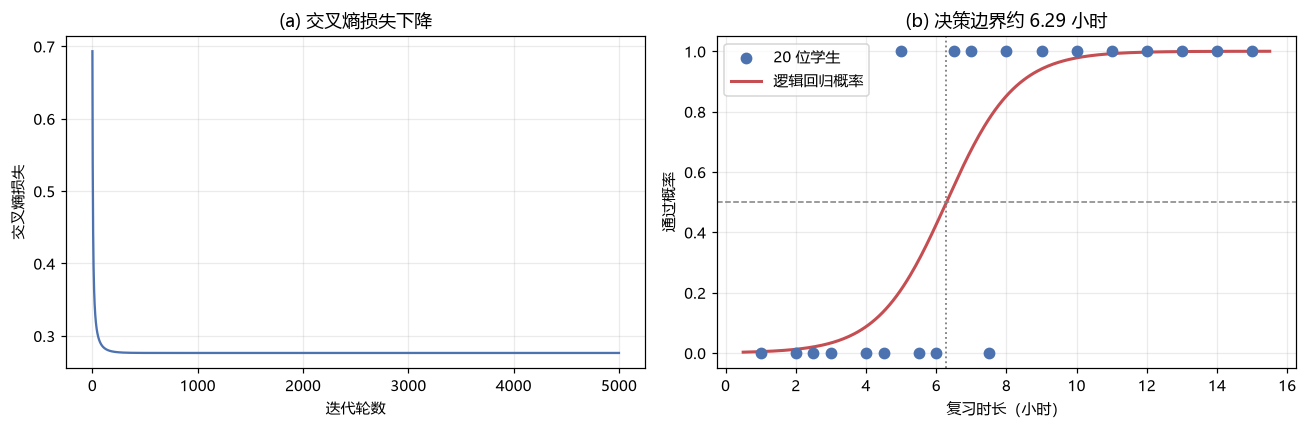

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(loss_history, color="#4C72B0")
axes[0].set_xlabel("迭代轮数")
axes[0].set_ylabel("交叉熵损失")
axes[0].set_title("(a) 交叉熵损失下降")
axes[0].grid(alpha=0.25)

x_grid = np.linspace(hours.min() - 0.5, hours.max() + 0.5, 300)
x_grid_scaled = (x_grid - x_mean) / x_sd
p_grid = sigmoid(w * x_grid_scaled + b)
axes[1].scatter(hours, passed, s=45, color="#4C72B0", zorder=3, label="20 位学生")
axes[1].plot(x_grid, p_grid, color="#C44E52", linewidth=2, label="逻辑回归概率")
axes[1].axhline(0.5, color="gray", linestyle="--", linewidth=1)
axes[1].axvline(boundary_hours, color="gray", linestyle=":", linewidth=1.2)
axes[1].set_xlabel("复习时长（小时）")
axes[1].set_ylabel("通过概率")
axes[1].set_title(f"(b) 决策边界约 {boundary_hours:.2f} 小时")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.savefig(IMAGES / "notes9_fig_gd_logistic.png", bbox_inches="tight")
plt.show()

手写梯度下降和 sklearn 得到的分类边界都落在 **6.3 小时左右**，训练集准确率都是 **0.90**。系数尺度不同，是因为 sklearn 默认带 L2 正则，而手写版本没有正则；但分类结果很接近。

逻辑回归的训练准确率高于“线性回归 + 0.5 阈值”的 0.85，更重要的是：它的输出是**概率**，可以按业务成本调阈值。

## 5. 完整案例：信贷违约预测

数据有 9 个特征：

- 数值特征：年龄、月收入、负债收入比、额度使用率、逾期次数、工作年限；
- 类别特征：学历、住房、职业。

建模流程：

1. 数值特征做 `StandardScaler`；
2. 类别特征做 `OneHotEncoder`；
3. 用 `ColumnTransformer` 组合预处理；
4. 用 `Pipeline` 把预处理和 `LogisticRegression` 绑在一起；
5. 分层划分训练集 / 测试集，测试集只在最后评估。

> 预处理必须放进 Pipeline。否则先用全体数据算均值/方差或做 One-Hot，测试集信息会泄露到训练过程。

In [11]:
numeric_features = [
    "年龄", "月收入", "负债收入比",
    "额度使用率", "逾期次数", "工作年限",
]
categorical_features = ["学历", "住房", "职业"]


def build_logistic_pipeline(C=1.0, class_weight=None):
    """构造预处理 + 逻辑回归的完整流水线。"""
    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_features),
    ])
    return Pipeline([
        ("prep", preprocessor),
        ("model", LogisticRegression(
            C=C,
            class_weight=class_weight,
            max_iter=2000,
            random_state=RANDOM_STATE,
        )),
    ])


X = df.drop(columns=["是否违约"])
y = df["是否违约"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

log_reg = build_logistic_pipeline().fit(X_train, y_train)
print("训练集:", X_train.shape, "测试集:", X_test.shape)
print(f"训练集违约率: {y_train.mean():.2%}")
print(f"测试集违约率: {y_test.mean():.2%}")

训练集: (4800, 9) 测试集: (1200, 9)
训练集违约率: 14.65%
测试集违约率: 14.67%


In [12]:
def evaluate(name, model, X_data, y_true, threshold=0.5):
    """统一计算分类指标与业务成本。"""
    proba = model.predict_proba(X_data)[:, 1]
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "模型": name,
        "阈值": threshold,
        "准确率": accuracy_score(y_true, pred),
        "精确率": precision_score(y_true, pred, zero_division=0),
        "召回率": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
        "FN": fn,
        "FP": fp,
        "成本(万元)": (FN_COST * fn + FP_COST * fp) / 10000,
    }


baseline = DummyClassifier(strategy="prior").fit(X_train, y_train)
compare_df = pd.DataFrame([
    evaluate("均值基线（全判未违约）", baseline, X_test, y_test),
    evaluate("逻辑回归 C=1，阈值 0.5", log_reg, X_test, y_test),
])
compare_df.round(4)

,模型,阈值,准确率,精确率,召回率,F1,ROC-AUC,PR-AUC,FN,FP,成本(万元)
0,均值基线（全判未违约）,0.5,0.8533,0.0000,0.0000,0.000,0.5000,0.1467,176,0,528.0
1,逻辑回归 C=1，阈值 0.5,0.5,0.8642,0.7407,0.1136,0.197,0.7711,0.4279,156,7,470.1


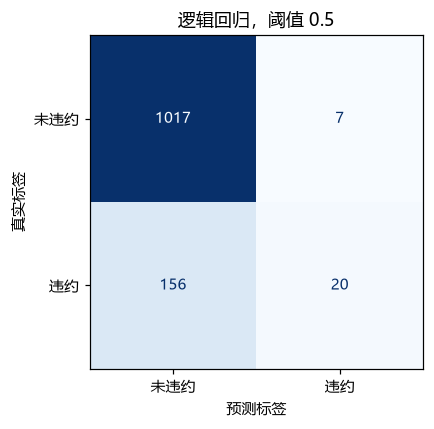

In [13]:
proba_default = log_reg.predict_proba(X_test)[:, 1]
pred_default = (proba_default >= 0.5).astype(int)
cm_default = confusion_matrix(y_test, pred_default)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    cm_default,
    display_labels=["未违约", "违约"],
).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("逻辑回归，阈值 0.5")
ax.set_xlabel("预测标签")
ax.set_ylabel("真实标签")
plt.setp(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.savefig(IMAGES / "notes9_fig_confusion_default.png", bbox_inches="tight")
plt.show()

In [14]:
print(classification_report(
    y_test,
    pred_default,
    target_names=["未违约", "违约"],
    digits=4,
    zero_division=0,
))

              precision    recall  f1-score   support

         未违约     0.8670    0.9932    0.9258      1024
          违约     0.7407    0.1136    0.1970       176

    accuracy                         0.8642      1200
   macro avg     0.8039    0.5534    0.5614      1200
weighted avg     0.8485    0.8642    0.8189      1200



阈值 0.5 时：

- 准确率 **86.42%**，看起来比均值基线 85.33% 高一点；
- 精确率 **74.07%**，但召回率只有 **11.36%**；
- 176 个违约者里，只抓到了 20 个，漏掉 **156 个**；
- 业务成本 **470.1 万元**。

这就是**准确率悖论**：多数类占 85.4%，模型只要偏向多数类就能拿到高准确率，但真正关心的少数类几乎没抓到。

> 下面改用 Precision / Recall / F1、ROC-AUC、PR-AUC 和业务成本来评估。

## 6. ROC、PR 与阈值

先复习混淆矩阵的四个格子（行 = 真实，列 = 预测）：

| | 预测为正 | 预测为负 |
|---|---:|---:|
| 真实为正 | TP | FN |
| 真实为负 | FP | TN |

由此得到：

$$
\text{Precision}=\frac{TP}{TP+FP},
\qquad
\text{Recall}=\frac{TP}{TP+FN},
\qquad
F_1=\frac{2\cdot P\cdot R}{P+R}
$$

- **ROC-AUC**：在所有阈值下，模型把正样本排在负样本前面的能力；对类别不平衡不够敏感；
- **PR-AUC（Average Precision）**：更关注少数类，类别不平衡时通常比 ROC-AUC 更有参考价值；
- **阈值**：不是模型参数，而是业务决策。阈值越低，召回率越高、精确率越低。

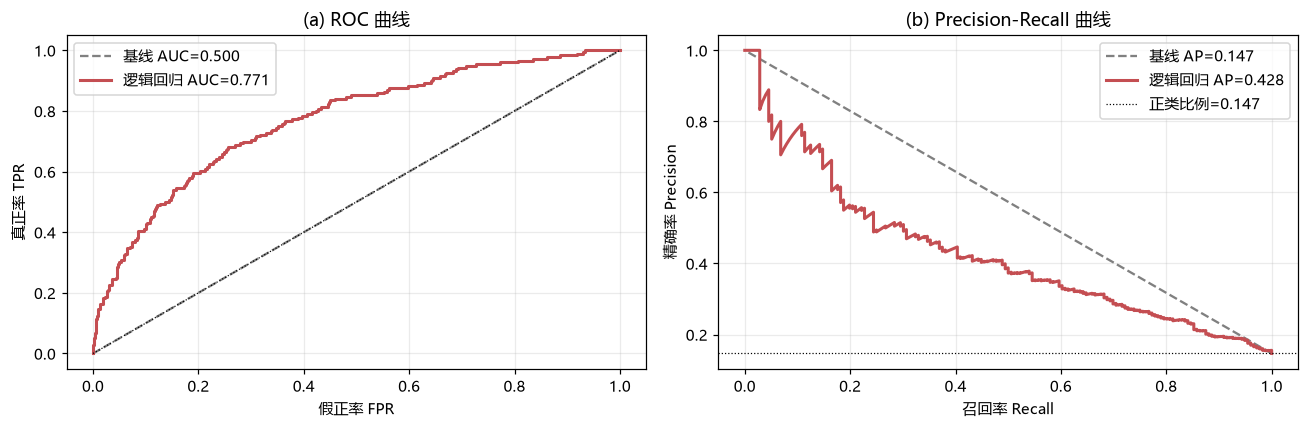

In [15]:
proba_base = baseline.predict_proba(X_test)[:, 1]
proba_log = log_reg.predict_proba(X_test)[:, 1]

fpr_b, tpr_b, _ = roc_curve(y_test, proba_base)
fpr_l, tpr_l, _ = roc_curve(y_test, proba_log)
prec_b, rec_b, _ = precision_recall_curve(y_test, proba_base)
prec_l, rec_l, _ = precision_recall_curve(y_test, proba_log)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(fpr_b, tpr_b, color="gray", linestyle="--", label=f"基线 AUC={auc(fpr_b, tpr_b):.3f}")
axes[0].plot(fpr_l, tpr_l, color="#C44E52", linewidth=2, label=f"逻辑回归 AUC={auc(fpr_l, tpr_l):.3f}")
axes[0].plot([0, 1], [0, 1], color="black", linewidth=0.8, linestyle=":")
axes[0].set_xlabel("假正率 FPR")
axes[0].set_ylabel("真正率 TPR")
axes[0].set_title("(a) ROC 曲线")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(
    rec_b, prec_b, color="gray", linestyle="--",
    label=f"基线 AP={average_precision_score(y_test, proba_base):.3f}",
)
axes[1].plot(
    rec_l, prec_l, color="#C44E52", linewidth=2,
    label=f"逻辑回归 AP={average_precision_score(y_test, proba_log):.3f}",
)
axes[1].axhline(
    y_test.mean(), color="black", linewidth=0.8, linestyle=":",
    label=f"正类比例={y_test.mean():.3f}",
)
axes[1].set_xlabel("召回率 Recall")
axes[1].set_ylabel("精确率 Precision")
axes[1].set_title("(b) Precision-Recall 曲线")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.savefig(IMAGES / "notes9_fig_roc_pr.png", bbox_inches="tight")
plt.show()

In [16]:
# 在训练集内部做 5 折交叉验证，得到每个样本的“折外”预测概率
# 这样调阈值只使用了训练数据，测试集仍然没有参与
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof_proba = cross_val_predict(
    build_logistic_pipeline(),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

thresholds = np.linspace(0.01, 0.99, 99)
threshold_rows = []
for t in thresholds:
    pred = (oof_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred, labels=[0, 1]).ravel()
    threshold_rows.append({
        "阈值": t,
        "精确率": precision_score(y_train, pred, zero_division=0),
        "召回率": recall_score(y_train, pred, zero_division=0),
        "F1": f1_score(y_train, pred, zero_division=0),
        "成本(万元)": (FN_COST * fn + FP_COST * fp) / 10000,
        "FN": fn,
        "FP": fp,
    })

threshold_df = pd.DataFrame(threshold_rows)
best_cost_row = threshold_df.loc[threshold_df["成本(万元)"].idxmin()]
best_f1_row = threshold_df.loc[threshold_df["F1"].idxmax()]

print(f"成本最优阈值: {best_cost_row['阈值']:.2f}，OOF 成本 {best_cost_row['成本(万元)']:.1f} 万元")
print(f"F1 最优阈值: {best_f1_row['阈值']:.2f}，OOF F1 {best_f1_row['F1']:.4f}")

成本最优阈值: 0.10，OOF 成本 931.8 万元
F1 最优阈值: 0.20，OOF F1 0.4212


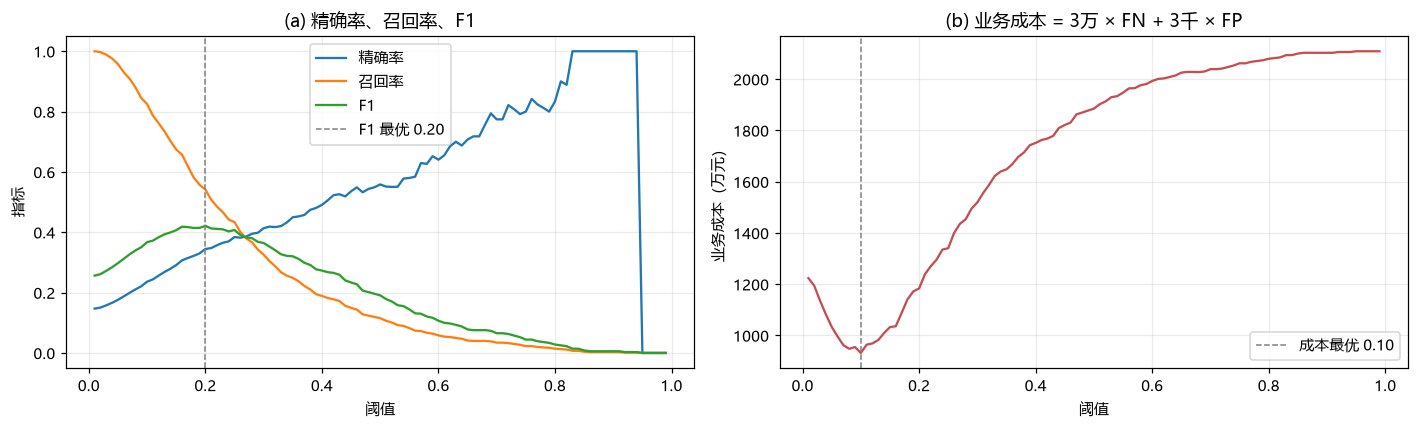

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(threshold_df["阈值"], threshold_df["精确率"], label="精确率")
axes[0].plot(threshold_df["阈值"], threshold_df["召回率"], label="召回率")
axes[0].plot(threshold_df["阈值"], threshold_df["F1"], label="F1")
axes[0].axvline(
    best_f1_row["阈值"], color="gray", linestyle="--", linewidth=1,
    label=f"F1 最优 {best_f1_row['阈值']:.2f}",
)
axes[0].set_xlabel("阈值")
axes[0].set_ylabel("指标")
axes[0].set_title("(a) 精确率、召回率、F1")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(threshold_df["阈值"], threshold_df["成本(万元)"], color="#C44E52")
axes[1].axvline(
    best_cost_row["阈值"], color="gray", linestyle="--", linewidth=1,
    label=f"成本最优 {best_cost_row['阈值']:.2f}",
)
axes[1].set_xlabel("阈值")
axes[1].set_ylabel("业务成本（万元）")
axes[1].set_title("(b) 业务成本 = 3万 × FN + 3千 × FP")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.savefig(IMAGES / "notes9_fig_threshold.png", bbox_inches="tight")
plt.show()

In [18]:
test_threshold_df = pd.DataFrame([
    evaluate("默认阈值 0.50", log_reg, X_test, y_test, 0.50),
    evaluate(f"F1 最优阈值 {best_f1_row['阈值']:.2f}", log_reg, X_test, y_test, best_f1_row["阈值"]),
    evaluate(f"成本最优阈值 {best_cost_row['阈值']:.2f}", log_reg, X_test, y_test, best_cost_row["阈值"]),
])
test_threshold_df.round(4)

,模型,阈值,准确率,精确率,召回率,F1,ROC-AUC,PR-AUC,FN,FP,成本(万元)
0,默认阈值 0.50,0.5,0.8642,0.7407,0.1136,0.1970,0.7711,0.4279,156,7,470.1
1,F1 最优阈值 0.20,0.2,0.7983,0.3721,0.5455,0.4424,0.7711,0.4279,80,162,288.6
2,成本最优阈值 0.10,0.1,0.6000,0.2424,0.8125,0.3734,0.7711,0.4279,33,447,233.1


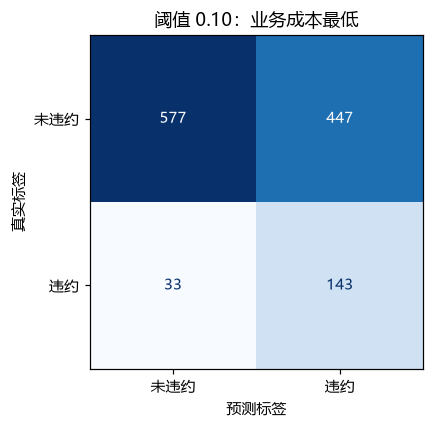

In [19]:
pred_cost = (proba_default >= best_cost_row["阈值"]).astype(int)
cm_cost = confusion_matrix(y_test, pred_cost)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    cm_cost,
    display_labels=["未违约", "违约"],
).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title(f"阈值 {best_cost_row['阈值']:.2f}：业务成本最低")
ax.set_xlabel("预测标签")
ax.set_ylabel("真实标签")
plt.setp(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.savefig(IMAGES / "notes9_fig_confusion_tuned.png", bbox_inches="tight")
plt.show()

结果对比（测试集）：

| 阈值 | 准确率 | 精确率 | 召回率 | F1 | 成本（万元） |
|---:|---:|---:|---:|---:|---:|
| 0.50 | 86.42% | 74.07% | 11.36% | 0.197 | 470.1 |
| 0.20（F1 最优） | 79.83% | 37.21% | 54.55% | 0.442 | 288.6 |
| 0.10（成本最优） | 60.00% | 24.24% | 81.25% | 0.373 | 233.1 |

准确率从 **86.42%** 掉到 **60.00%**，但业务成本从 **470.1 万**降到 **233.1 万**，召回率从 **11.36%** 提高到 **81.25%**。

对信贷审批来说，漏掉一个违约者损失 3 万元，误伤一个好客户只损失 3000 元，所以**低阈值、高召回**更划算。阈值 0.10 是在训练集的折外预测上选的，测试集只用于最终评估。

## 7. 类别不平衡与 `class_weight`

除了调阈值，还可以在训练时给少数类更大的权重：

```python
LogisticRegression(class_weight="balanced")
```

`balanced` 会按类别频率的反比加权，让少数类的样本在损失里“说话更响”。

代价是：预测概率的尺度会改变，精确率通常下降、召回率上升；如果后续要用概率做业务决策，需要重新校准或重新调阈值。

In [20]:
log_reg_balanced = build_logistic_pipeline(class_weight="balanced").fit(X_train, y_train)

balanced_df = pd.DataFrame([
    evaluate("默认 C=1", log_reg, X_test, y_test, 0.5),
    evaluate("class_weight='balanced'", log_reg_balanced, X_test, y_test, 0.5),
])
balanced_df.round(4)

,模型,阈值,准确率,精确率,召回率,F1,ROC-AUC,PR-AUC,FN,FP,成本(万元)
0,默认 C=1,0.5,0.8642,0.7407,0.1136,0.1970,0.7711,0.4279,156,7,470.1
1,class_weight='balanced',0.5,0.7192,0.2982,0.6761,0.4139,0.7692,0.4208,57,280,255.0


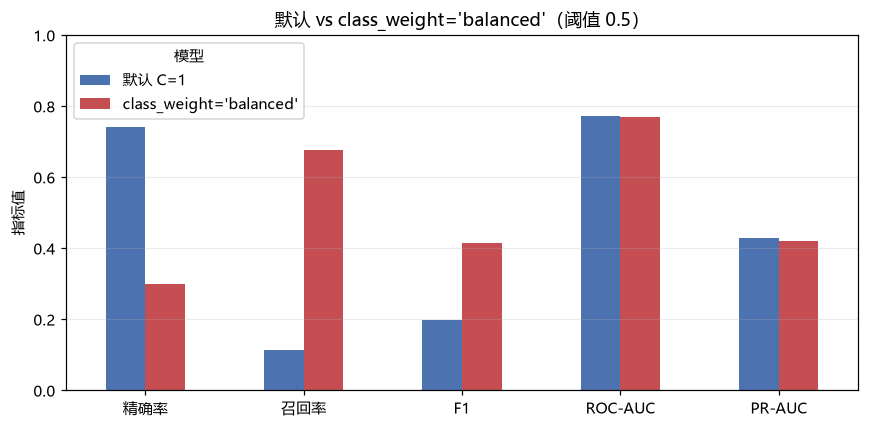

In [21]:
metric_cols = ["精确率", "召回率", "F1", "ROC-AUC", "PR-AUC"]
plot_df = balanced_df.set_index("模型")[metric_cols].T

fig, ax = plt.subplots(figsize=(8, 4))
plot_df.plot(kind="bar", ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_ylabel("指标值")
ax.set_title("默认 vs class_weight='balanced'（阈值 0.5）")
ax.set_ylim(0, 1.0)
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.legend(title="模型")
plt.tight_layout()
plt.savefig(IMAGES / "notes9_fig_class_weight.png", bbox_inches="tight")
plt.show()

`class_weight='balanced'` 的效果：

- 准确率从 86.42% 降到 71.92%；
- 召回率从 11.36% 升到 67.61%；
- F1 从 0.197 升到 0.414；
- 业务成本从 470.1 万降到 **255.0 万**。

它和“默认模型 + 低阈值”是两条思路：

- 默认模型 + 阈值 0.10：成本 **233.1 万**，召回率 81.25%，精确率 24.24%；
- `balanced` + 阈值 0.50：成本 **255.0 万**，召回率 67.61%，精确率 29.82%。

两种都可以，关键是用验证集/OOF 选方案，再用测试集做最终评估。`balanced` 的概率不再等于真实违约频率，不能直接拿“0.5 = 50% 概率”做业务解释。

## 8. 正则化与 `C`

逻辑回归默认使用 L2 正则。`C` 是正则强度的倒数：

- `C` 越小，正则越强，系数被压得越厉害；
- `C` 越大，正则越弱，越接近无正则；
- `C` 太小会欠拟合，`C` 太大会过拟合。

做正则化前必须先标准化，否则惩罚对量纲大的特征不公平。

`scoring` 的选择也很重要：类别不平衡时，用 `average_precision`（PR-AUC）通常比 accuracy 更合适。`C` 只能在训练集上通过交叉验证选，测试集不能参与。

In [22]:
param_grid = {"model__C": [0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(
    build_logistic_pipeline(),
    param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
)
grid.fit(X_train, y_train)

print("最优参数:", grid.best_params_)
print(f"最优交叉验证 PR-AUC: {grid.best_score_:.4f}")

cv_table = pd.DataFrame({
    "C": [p["model__C"] for p in grid.cv_results_["params"]],
    "CV PR-AUC 均值": grid.cv_results_["mean_test_score"],
    "标准差": grid.cv_results_["std_test_score"],
}).sort_values("C")
cv_table.round(4)

最优参数: {'model__C': 1}
最优交叉验证 PR-AUC: 0.3810


,C,CV PR-AUC 均值,标准差
0,0.01,0.3670,0.0422
1,0.10,0.3790,0.0378
2,1.00,0.3810,0.0365
3,10.00,0.3806,0.0366
4,100.00,0.3806,0.0366


In [23]:
best_log_reg = grid.best_estimator_
best_df = pd.DataFrame([
    evaluate("默认 C=1", log_reg, X_test, y_test, 0.5),
    evaluate(f"CV 最优 C={grid.best_params_['model__C']}", best_log_reg, X_test, y_test, 0.5),
])
best_df.round(4)

,模型,阈值,准确率,精确率,召回率,F1,ROC-AUC,PR-AUC,FN,FP,成本(万元)
0,默认 C=1,0.5,0.8642,0.7407,0.1136,0.197,0.7711,0.4279,156,7,470.1
1,CV 最优 C=1,0.5,0.8642,0.7407,0.1136,0.197,0.7711,0.4279,156,7,470.1


交叉验证选择了 **C=1**，也就是 sklearn 的默认强度。`C=0.01` 的 CV PR-AUC 略低，说明正则太强；`C=10/100` 与 `C=1` 差别很小，说明这份数据没有明显的过拟合。

测试集 PR-AUC 约 **0.428**，高于正类比例 0.147，说明模型确实学到了区分违约者的信息；但 ROC-AUC 只有 0.771，仍有提升空间。

## 9. 系数解释：谁在推高违约概率

逻辑回归的系数是**对数几率**（log-odds）：

$$
z=w^\top x+b
$$

某个特征系数为 `w_j`，在其他特征不变时，`x_j` 增加 1 个单位，对数几率增加 `w_j`，优势比（odds ratio）变为 `exp(w_j)` 倍。

注意：

- 数值特征已经标准化，所以系数是“每变化 1 个标准差”的效果，不是每 1 元/每 1 岁；
- 类别特征做了 One-Hot 且 `drop="first"`，系数是相对**参考类别**的效果；
- 这是控制其他变量后的**条件关联**，不是因果效应；相关特征之间会互相影响。

In [24]:
feature_names = log_reg.named_steps["prep"].get_feature_names_out()
coefs = log_reg.named_steps["model"].coef_[0]

coef_df = pd.DataFrame({
    "特征": [n.replace("num__", "").replace("cat__", "") for n in feature_names],
    "系数": coefs,
    "优势比": np.exp(coefs),
})
coef_df["|系数|"] = coef_df["系数"].abs()
coef_df = coef_df.sort_values("|系数|", ascending=False).drop(columns="|系数|")
coef_df.head(15).round(4)

,特征,系数,优势比
12,职业_公职,-1.4913,0.2251
11,职业_互联网,-0.8488,0.4279
13,职业_制造业,-0.8120,0.4440
10,住房_租房,0.6375,1.8918
4,逾期次数,0.5399,1.7158
2,负债收入比,0.4519,1.5713
9,住房_有房贷,0.4072,1.5026
3,额度使用率,0.3183,1.3748
7,学历_硕士及以上,-0.3062,0.7362
14,职业_餐饮零售,-0.2665,0.7661


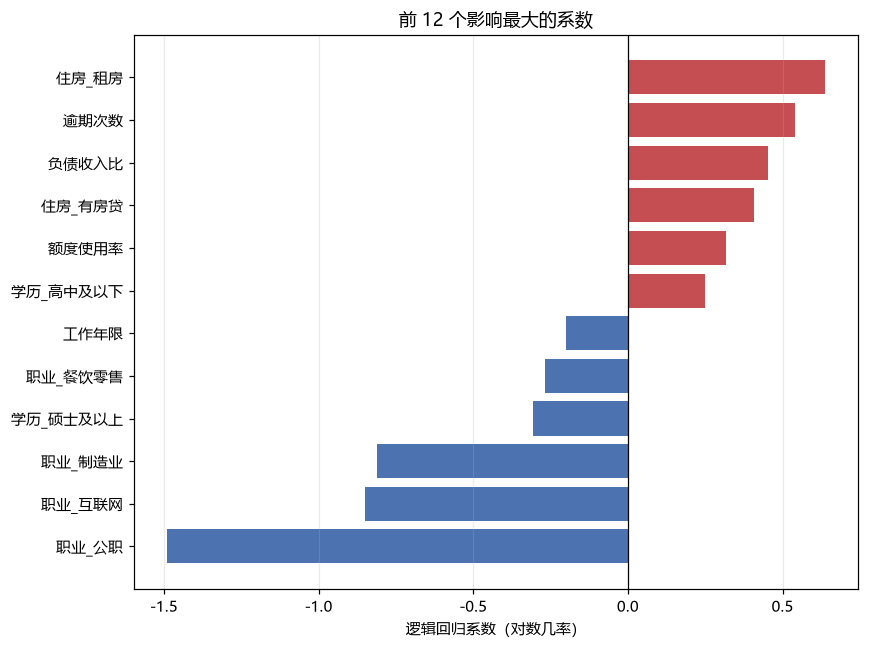

In [25]:
plot_df = coef_df.head(12).sort_values("系数")
colors = ["#C44E52" if value > 0 else "#4C72B0" for value in plot_df["系数"]]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(plot_df["特征"], plot_df["系数"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("逻辑回归系数（对数几率）")
ax.set_title("前 12 个影响最大的系数")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(IMAGES / "notes9_fig_coef.png", bbox_inches="tight")
plt.show()

按绝对系数排序，前几项是：

| 特征 | 系数 | 优势比 | 读法 |
|---|---:|---:|---|
| 职业_公职 | -1.491 | 0.225 | 相对“个体经营”，公职申请人违约几率约为 0.225 倍 |
| 职业_互联网 | -0.849 | 0.428 | 相对“个体经营”，互联网从业者违约几率约为 0.428 倍 |
| 职业_制造业 | -0.812 | 0.444 | 相对“个体经营”，制造业从业者违约几率约为 0.444 倍 |
| 住房_租房 | +0.638 | 1.892 | 相对“全款房”，租房者违约几率约为 1.892 倍 |
| 逾期次数 | +0.540 | 1.716 | 每增加 1 个标准差（约 0.82 次逾期），违约几率约 1.716 倍 |
| 负债收入比 | +0.452 | 1.571 | 每增加 1 个标准差，违约几率约 1.571 倍 |
| 住房_有房贷 | +0.407 | 1.503 | 相对“全款房”，有房贷者违约几率约 1.503 倍 |
| 额度使用率 | +0.318 | 1.375 | 每增加 1 个标准差，违约几率约 1.375 倍 |

参考类别：职业 = 个体经营，住房 = 全款房，学历 = 大专。

注意：`月收入` 的系数是 **-0.190**，不能直接解释成“收入越高越容易违约”。这是控制年龄、职业、负债收入比等变量后的条件关联，可能受到特征相关性和数据生成方式影响。要做业务解释，最好结合单变量分析、分组统计和因果实验。

## 10. 结论与注意点

### 结论

1. 逻辑回归不是回归算法，而是**二分类算法**；它输出正类概率 `p = σ(wᵀx+b)`。
2. Sigmoid 把线性得分压到 `(0,1)`；导数 `σ'(z)=σ(z)(1-σ(z))`，最大值 0.25。
3. 训练逻辑回归用**交叉熵**，不用 MSE；交叉熵 + Sigmoid 的梯度形式是 `p-y`，误差越大更新越大。
4. 这份信贷数据有 6000 条、9 个特征，违约率 14.6%，是明显的类别不平衡数据。
5. 均值基线的准确率有 85.33%，但召回率为 0，业务成本 528.0 万元；**准确率高不代表模型有用**。
6. 默认逻辑回归阈值 0.5：准确率 86.42%，召回率 11.36%，成本 470.1 万元，漏掉 156 个违约者。
7. 在训练集折外预测上把阈值调到 0.10：准确率降到 60.00%，召回率升到 81.25%，成本降到 **233.1 万元**。
8. `class_weight='balanced'` 也能提高召回率：阈值 0.5 时召回率 67.61%，成本 255.0 万元；但概率尺度会变，需要重新校准或调阈值。
9. 正则化参数 `C` 用交叉验证选，这份数据最优是 `C=1`；测试集 PR-AUC 约 0.428。
10. 预处理必须放进 Pipeline：先标准化/One-Hot 再划分，会数据泄露。

### 讲义订正

- 第 56 页代码输出 `准确率：0.83` 是在 **23 个样本**上算的；正文说“原来 20 人的准确率降到 80%”是只看 **原 20 人**。两个数口径不同，不矛盾。
- 第 53 页“判断一张图片是不是垃圾短信”表述有误，应为“判断一条短信是不是垃圾短信”。

### 注意点

1. **阈值不是模型参数**：同一模型在不同阈值下有不同的精确率/召回率/成本；阈值要用验证集或 OOF 选。
2. **不要用测试集调阈值、选 `C`、选 `class_weight`**，否则测试集就不再是公正评估。
3. **类别不平衡时优先看 PR-AUC、召回率和业务成本**，不要只报 accuracy。
4. **`class_weight='balanced'` 会改变概率尺度**，预测概率不再等于真实违约频率；要概率校准就用 `CalibratedClassifierCV`。
5. **逻辑回归假设 log-odds 与特征线性相关**；如果关系明显非线性，需要多项式/交互项，或改用树模型。
6. **系数是条件关联，不是因果**；相关特征之间会互相影响，解释时要谨慎。
7. **数据是课程示例数据**，结论用于练习建模流程，不代表真实金融机构的风控结论。

### 练习

1. 把 FN 成本改成 5 万元、FP 成本改成 1000 元，重新在 OOF 上选阈值，观察最优阈值和测试成本怎么变。
2. 用 `class_weight='balanced'` 训练后，再在 OOF 上重新调阈值，比较它和“默认模型 + 低阈值”的成本。
3. 用 `GridSearchCV` 同时搜索 `C` 和 `class_weight`，`scoring` 分别用 `roc_auc`、`average_precision`、`recall`，比较选出的参数。
4. 用 `LogisticRegression(l1_ratio=1.0, solver="liblinear")` 做 L1 正则，统计非零系数数量，并和 L2 的系数对比。
5. 画校准曲线（calibration curve），检查预测概率是否接近真实违约频率；再比较 `class_weight='balanced'` 前后的校准情况。
6. 比较 `OneHotEncoder(drop="first")` 与 `drop=None` 的系数、预测结果和共线性。
7. 加入交互项或多项式特征（例如“逾期次数 × 负债收入比”），看 PR-AUC 是否提升；注意用 Pipeline 避免泄露。
8. 用 `StratifiedKFold` 的 OOF 概率调阈值，并向同学解释：为什么不能直接拿测试集调阈值。